# CAR-T cell state trajectories with a conditional VAE
Conditional VAE (PyTorch) on 62,167 CD8⁺ CD19 CAR-T cells from 4 patients ([GSE125881](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE125881), Sheih et al. 2020), conditioned on **patient**. Day post-infusion is never given to the model; it's used afterwards to check whether the latent space tracks real time.

## 1. Load the data

In [1]:
# Download the GEO count matrix and peek at it before loading: rows = genes, columns = cells (62,167),
# barcodes carry no sample name, only a -1..-16 suffix
!wget -q https://ftp.ncbi.nlm.nih.gov/geo/series/GSE125nnn/GSE125881/suppl/GSE125881_raw.expMatrix.csv.gz

import pandas as pd
peek = pd.read_csv("GSE125881_raw.expMatrix.csv.gz", nrows=5, index_col=0)
print(peek.shape)
print(peek.iloc[:5, :5])
print(list(peek.columns[:5]))

(5, 62167)
               AAACCTGAGCGTCTAT-1  AAACCTGCAATAGAGT-1  AAACCTGCATGACGGA-1  \
RP11-34P13.7                    0                   0                   0   
FO538757.3                      0                   0                   0   
FO538757.2                      1                   1                   0   
AP006222.2                      0                   0                   0   
RP4-669L17.10                   0                   0                   0   

               AAACCTGGTAGTGAAT-1  AAACCTGGTCTCCCTA-1  
RP11-34P13.7                    0                   0  
FO538757.3                      0                   0  
FO538757.2                      1                   2  
AP006222.2                      0                   0  
RP4-669L17.10                   0                   0  
['AAACCTGAGCGTCTAT-1', 'AAACCTGCAATAGAGT-1', 'AAACCTGCATGACGGA-1', 'AAACCTGGTAGTGAAT-1', 'AAACCTGGTCTCCCTA-1']


In [2]:
!pip install scanpy
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import numpy as np, pandas as pd, scipy.sparse as sp, anndata as ad

# Read 1,000 genes at a time and convert each chunk to sparse immediately, so the full dense
# 20k x 62k table is never held in RAM (loading it in one go crashes Colab)
PATH = "GSE125881_raw.expMatrix.csv.gz"
chunks, genes = [], []
for chunk in pd.read_csv(PATH, index_col=0, chunksize=1000):
    genes.extend(chunk.index)
    chunks.append(sp.csr_matrix(chunk.to_numpy(dtype=np.float32)))
    cells = chunk.columns
    print(f"read {len(genes):,} genes", end="\r")

X = sp.vstack(chunks).T.tocsr()          # genes x cells -> cells x genes (Scanpy wants cells as rows)
adata = ad.AnnData(X=X,
                   obs=pd.DataFrame(index=cells.astype(str)),
                   var=pd.DataFrame(index=pd.Index(genes).astype(str)))
adata.var_names_make_unique()
# Suffix -1..-16 = which of the 16 merged 10x samples the cell came from
adata.obs["suffix"] = adata.obs_names.str.split("-").str[-1].astype(int)

print("\n", adata)
print(adata.obs["suffix"].value_counts().sort_index())



 AnnData object with n_obs × n_vars = 62167 × 20223
    obs: 'suffix'
    layers: None (.X)
suffix
1     5515
2     6722
3     4920
4     1736
5     6117
6     6488
7     5023
8     1763
9     6271
10    4287
11     669
12    3484
13    2459
14    2382
15     197
16    4134
Name: count, dtype: int64


In [3]:
# Save locally first (seconds), so the parsed data survives if the Drive mount fails
adata.write_h5ad("/content/GSE125881_raw.h5ad")

In [5]:
# Copy to Drive: Colab wipes local files when the session ends
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
!cp /content/GSE125881_raw.h5ad /content/drive/MyDrive/

Mounted at /content/drive


## 2. Which barcode suffix is which sample?
GEO doesn't document how the `-1`…`-16` suffixes map to samples. The per-sample TCR files share cell barcodes with the expression data, so overlapping them verifies the mapping.

In [6]:
# GEO's per-sample TCR (VDJ) files. Each was sequenced from the same cells as one expression sample,
# so its barcodes tell us which suffix belongs to which sample
!wget -q https://ftp.ncbi.nlm.nih.gov/geo/series/GSE125nnn/GSE125881/suppl/GSE125881_RAW.tar
!mkdir -p raw_tar && tar -xf GSE125881_RAW.tar -C raw_tar && ls raw_tar

GSM3583877_CLL-1_IP-unpaired-clonotypes.csv.gz
GSM3583878_CLL-1_d21-unpaired-clonotypes.csv.gz
GSM3583879_CLL-1_d38-unpaired-clonotypes.csv.gz
GSM3583880_CLL-1_d112-unpaired-clonotypes.csv.gz
GSM3583881_CLL-2_IP-unpaired-clonotypes.csv.gz
GSM3583882_CLL-2_d12-unpaired-clonotypes.csv.gz
GSM3583883_CLL-2_d29-unpaired-clonotypes.csv.gz
GSM3583884_CLL-2_d83-unpaired-clonotypes.csv.gz
GSM3583885_NHL-6_IP-unpaired-clonotypes.csv.gz
GSM3583886_NHL-6_d12-unpaired-clonotypes.csv.gz
GSM3583887_NHL-6_d29-unpaired-clonotypes.csv.gz
GSM3583888_NHL-6_d102-unpaired-clonotypes.csv.gz
GSM3583889_NHL-7_IP-unpaired-clonotypes.csv.gz
GSM3583890_NHL-7_d12-unpaired-clonotypes.csv.gz
GSM3583891_NHL-7_d28-unpaired-clonotypes.csv.gz
GSM3583892_NHL-7_d89-unpaired-clonotypes.csv.gz


In [7]:
# Verify suffix -> sample: % of each VDJ file's barcodes found under each suffix.
# A clean diagonal = one-to-one mapping. Result: the order does NOT follow GEO's sample list
# (only CLL-1 lines up), so guessing it would have mislabeled ~70% of cells
import glob, gzip, os, re
import pandas as pd

# barcode "core" (the 16 letters) and suffix for every cell in the expression matrix
core = adata.obs_names.str.split("-").str[0]
suffix = adata.obs_names.str.split("-").str[-1].astype(int)
matrix_sets = {k: set(core[suffix == k]) for k in sorted(set(suffix))}

files = sorted(glob.glob("raw_tar/*.csv.gz"))
print(pd.read_csv(files[0]).head(3), "\n")       # peek: what columns do these files have?

overlap = {}
for f in files:
    text = gzip.open(f, "rt").read()
    file_bcs = set(re.findall(r"[ACGT]{16}", text))   # every barcode anywhere in the file
    name = os.path.basename(f).split("_", 1)[1].replace("-unpaired-clonotypes.csv.gz", "")
    overlap[name] = {k: len(file_bcs & s) / max(len(file_bcs), 1) for k, s in matrix_sets.items()}

overlap = pd.DataFrame(overlap).T                 # rows = GEO sample, columns = suffix
print((overlap * 100).round(0).astype(int).to_string())   # % of each file's barcodes found per suffix

  chain                                      clonotype_ids  \
0   TRB  clonotype1;clonotype5;clonotype1799;clonotype4...   
1   TRA  clonotype1;clonotype1799;clonotype4166;clonoty...   
2   TRB  clonotype2;clonotype18;clonotype952;clonotype2...   

                                       consensus_ids  \
0  clonotype1_consensus_1;clonotype5_consensus_1;...   
1  clonotype1_consensus_2;clonotype1799_consensus...   
2  clonotype2_consensus_1;clonotype18_consensus_1...   

                                            barcodes  \
0  AAACGGGCACGTAAGG-1;CTCGTCATCTGTTGAG-1;CTGCGGAC...   
1  ACCGTAAGTTGTGGAG-1;GGTGTTAGTATCAGTC-1;CACACAAG...   
2  GACGTGCAGGATGGAA-1;GATGAAAAGGGTGTTG-1;GATGAGGT...   

                                          contig_ids                cdr3s  \
0  AAACGGGCACGTAAGG-1_contig_1;AAACGGGGTCCTCCAT-1...     CASSPNQHSGANVLTF   
1  AAACGGGCACGTAAGG-1_contig_4;AAACGGGGTCCTCCAT-1...     CLVGDMRTGGGNKLTF   
2  AACTGGTGTCTTCAAG-1_contig_1;AACTGGTGTTGAGGTG-1...  CSVEGVWQGTTNSGNT

In [8]:
# Mapping read off the overlap table above (not GEO order)
SUFFIX_MAP = {
    1: ("CLL-1", "IP"),   2: ("CLL-1", "d21"),  3: ("CLL-1", "d38"),  4: ("CLL-1", "d112"),
    8: ("CLL-2", "IP"),   9: ("CLL-2", "d12"),  10: ("CLL-2", "d29"), 11: ("CLL-2", "d83"),
    16: ("NHL-6", "IP"),  5: ("NHL-6", "d12"),  6: ("NHL-6", "d29"),  7: ("NHL-6", "d102"),
    12: ("NHL-7", "IP"),  13: ("NHL-7", "d12"), 14: ("NHL-7", "d28"), 15: ("NHL-7", "d89"),
}
adata.obs["patient"] = adata.obs["suffix"].map(lambda k: SUFFIX_MAP[k][0]).astype("category")
adata.obs["timepoint"] = adata.obs["suffix"].map(lambda k: SUFFIX_MAP[k][1])
adata.obs["day"] = adata.obs["timepoint"].str.replace("IP", "d0").str[1:].astype(int)   # numeric, IP = 0
adata.obs["disease"] = adata.obs["patient"].str.split("-").str[0]

print(pd.crosstab(adata.obs["patient"], adata.obs["timepoint"]))
adata.write_h5ad("/content/drive/MyDrive/GSE125881_raw.h5ad")   # overwrite with labels included

timepoint    IP  d102  d112   d12   d21   d28   d29   d38  d83  d89
patient                                                            
CLL-1      5515     0  1736     0  6722     0     0  4920    0    0
CLL-2      1763     0     0  6271     0     0  4287     0  669    0
NHL-6      4134  5023     0  6117     0     0  6488     0    0    0
NHL-7      3484     0     0  2459     0  2382     0     0    0  197


In [9]:
# Chronological order for plots (otherwise d102 sorts before d12)
order = ["IP", "d12", "d21", "d28", "d29", "d38", "d83", "d89", "d102", "d112"]
adata.obs["timepoint"] = pd.Categorical(adata.obs["timepoint"], categories=order, ordered=True)

## 3. QC, normalization, gene selection

mito genes found: 13
       n_genes_by_counts  total_counts  pct_counts_mt
count            62167.0       62167.0        62167.0
mean              1874.1        5688.7            5.1
std                781.5        3759.2            3.3
min                291.0         533.0            0.0
25%               1406.0        3616.0            3.2
50%               1791.0        4905.0            4.1
75%               2210.0        6609.5            5.5
max               6032.0       39347.0           20.0


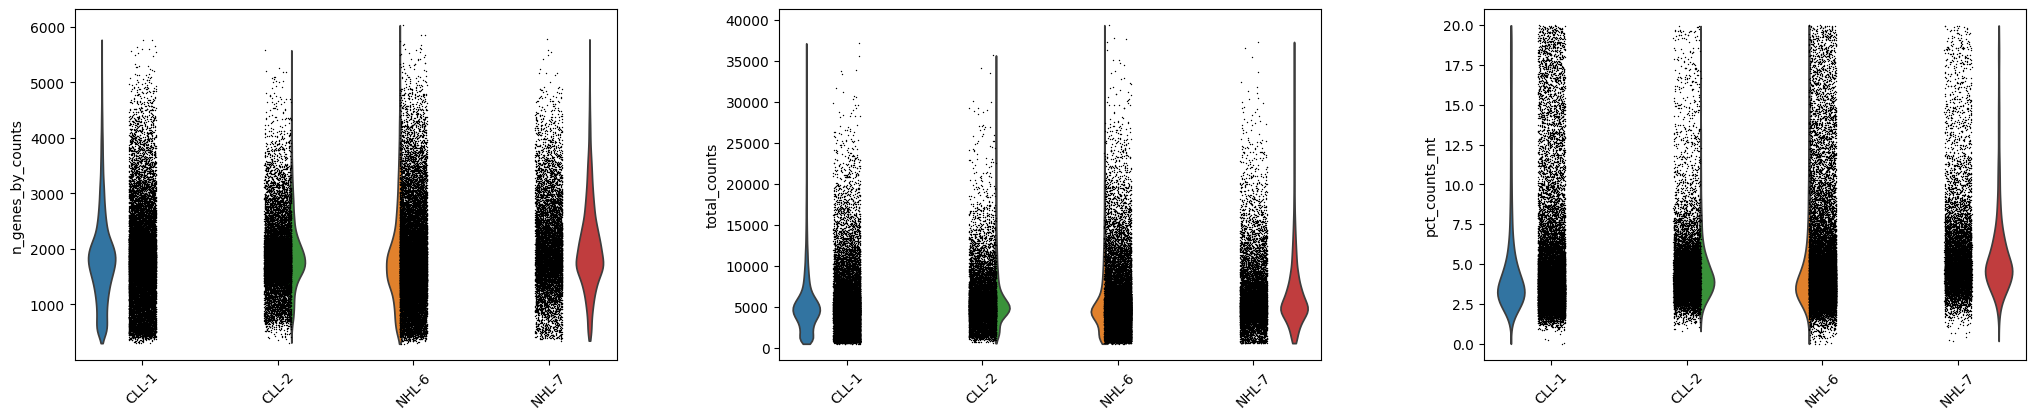

In [10]:
# QC check: the authors already filtered this matrix (mito % capped at exactly 20, >=291 genes/cell),
# so no extra cell filtering, just look at the distributions
import scanpy as sc

adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

print("mito genes found:", adata.var["mt"].sum())
print(adata.obs[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].describe().round(1))
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             groupby="patient", multi_panel=True, rotation=45)

In [11]:
# 1. Drop genes seen in almost no cells (they carry no signal, just noise)
sc.pp.filter_genes(adata, min_cells=10)

# 2. Doublet scores, computed per sample (doublets only form within a 10x run)
sc.pp.scrublet(adata, batch_key="suffix")
print(adata.obs["predicted_doublet"].value_counts())
print(pd.crosstab(adata.obs["patient"], adata.obs["predicted_doublet"]))
adata = adata[~adata.obs["predicted_doublet"]].copy()

# 3. Keep raw counts, then normalize + log on ALL genes
#    (before HVG selection, so library size isn't estimated from only 2,000 genes)
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# 4. Highly variable genes, chosen within each patient so one patient can't dominate
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="patient")
markers = ["TCF7","SELL","IL7R","CCR7","LEF1","PDCD1","HAVCR2","LAG3","TOX","TIGIT","CTLA4","ENTPD1"]
# Several exhaustion markers (PDCD1, HAVCR2, TOX...) are NOT highly variable here -> added back before training
print({g: bool(adata.var.loc[g, "highly_variable"]) for g in markers if g in adata.var_names})

predicted_doublet
False    61911
True       256
Name: count, dtype: int64
predicted_doublet  False  True 
patient                        
CLL-1              18888      5
CLL-2              12909     81
NHL-6              21754      8
NHL-7               8360    162
{'TCF7': True, 'SELL': True, 'IL7R': True, 'CCR7': True, 'LEF1': False, 'PDCD1': False, 'HAVCR2': False, 'LAG3': True, 'TOX': False, 'TIGIT': False, 'CTLA4': False, 'ENTPD1': False}


In [12]:
# .h5ad only allows string keys. Scrublet stored per-batch results keyed by the integer suffix,
# which made the save in the previous cell fail, so convert keys to strings and save
def stringify_keys(d):
    if isinstance(d, dict):
        return {str(k): stringify_keys(v) for k, v in d.items()}
    return d

adata.uns = stringify_keys(dict(adata.uns))
adata.write_h5ad("/content/drive/MyDrive/GSE125881_qc_lognorm.h5ad")

## 4. Model code
Sections 0–4 of `cvae_cart_exhaustion.py`: imports/config, data prep, encoder/decoder, loss (MSE reconstruction + β·KL), training loop with KL warm-up and early stopping.

In [13]:
"""
Conditional VAE (CVAE) for CAR-T / T cell exhaustion trajectories from scRNA-seq.

Designed to drop into cart_exhaustion_pipeline.ipynb (Colab) after Phase 0 (QC).
Each numbered section can be pasted into its own notebook cell.

Pipeline:
  1. Prepare data   – AnnData -> log-normalized matrix + one-hot condition labels
  2. Model          – Encoder(x, c) -> (mu, logvar); Decoder(z, c) -> x_hat
  3. Loss           – reconstruction (MSE on log-normalized data) + beta * KL
  4. Train          – Adam, KL warm-up, early stopping on validation loss
  5. Embed          – latent means -> adata.obsm["X_cvae"], UMAP + diffusion pseudotime
  6. Trajectory     – interpolate functional -> exhausted in latent space, decode, rank genes
  7. Counterfactual – swap the condition label for the same cells, see which genes move
"""

# 0. Imports and config
!pip install scanpy
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Defaults from the first draft; the training cell below overrides them
# (condition_key='patient', latent_dim=10, hidden_dims=[256, 128], batch_size=512)
CONFIG = {
    "condition_key": "dataset_id",  # column in adata.obs to condition on (donor, batch, dataset, timepoint...)
    "latent_dim": 5,                # small panel -> small latent space; raise to 10-20 with ~2,000 HVGs
    "hidden_dims": [64, 32],        # encoder layer sizes (decoder mirrors them)
    "dropout": 0.1,
    "batch_size": 256,
    "lr": 1e-3,
    "max_epochs": 300,
    "kl_warmup_epochs": 50,         # beta ramps 0 -> beta_max over these epochs
    "beta_max": 1.0,
    "patience": 30,                 # early stopping
    "val_fraction": 0.1,
}

# Marker sets used to define the two ends of the trajectory (only genes present in the data are used)
FUNCTIONAL_MARKERS = ["TCF7", "SELL", "IL7R", "CCR7", "LEF1"]
EXHAUSTED_MARKERS = ["PDCD1", "HAVCR2", "LAG3", "TOX", "TIGIT", "CTLA4", "ENTPD1"]


In [14]:
# 1. Prepare data
def prepare_data(adata, condition_key, already_log_normalized=False):
    """
    Returns
      X        : float32 array (cells x genes), log-normalized
      C        : float32 one-hot array (cells x n_conditions)
      cond_cats: list of condition category names (column order of C)
    Raw counts are kept in adata.layers["counts"] so you can switch to a count likelihood later.
    """
    adata = adata.copy()
    if not already_log_normalized:
        adata.layers["counts"] = adata.X.copy()
        sc.pp.normalize_total(adata, target_sum=1e4)
        sc.pp.log1p(adata)

    X = adata.X.toarray() if sp.issparse(adata.X) else np.asarray(adata.X)
    X = X.astype(np.float32)

    cond = adata.obs[condition_key].astype("category")
    cond_cats = list(cond.cat.categories)
    C = np.eye(len(cond_cats), dtype=np.float32)[cond.cat.codes.to_numpy()]

    return adata, X, C, cond_cats


def make_loaders(X, C, val_fraction, batch_size, seed=SEED):
    n = X.shape[0]
    rng = np.random.default_rng(seed)
    idx = rng.permutation(n)
    n_val = int(n * val_fraction)
    val_idx, train_idx = idx[:n_val], idx[n_val:]

    def loader(ix, shuffle):
        ds = TensorDataset(torch.from_numpy(X[ix]), torch.from_numpy(C[ix]))
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

    return loader(train_idx, True), loader(val_idx, False)


In [15]:
# 2. Model
def mlp(in_dim, hidden_dims, dropout):
    layers, d = [], in_dim
    for h in hidden_dims:
        layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
        d = h
    return nn.Sequential(*layers), d


class Encoder(nn.Module):
    """q(z | x, c): maps a cell + its condition to a Gaussian over latent space."""
    def __init__(self, n_genes, n_cond, hidden_dims, latent_dim, dropout):
        super().__init__()
        self.body, d = mlp(n_genes + n_cond, hidden_dims, dropout)
        self.mu = nn.Linear(d, latent_dim)
        self.logvar = nn.Linear(d, latent_dim)

    def forward(self, x, c):
        h = self.body(torch.cat([x, c], dim=1))
        return self.mu(h), self.logvar(h)


class Decoder(nn.Module):
    """p(x | z, c): reconstructs log-expression from a latent point + condition."""
    def __init__(self, n_genes, n_cond, hidden_dims, latent_dim, dropout):
        super().__init__()
        self.body, d = mlp(latent_dim + n_cond, list(reversed(hidden_dims)), dropout)
        self.out = nn.Linear(d, n_genes)

    def forward(self, z, c):
        h = self.body(torch.cat([z, c], dim=1))
        return F.softplus(self.out(h))  # log1p expression is non-negative


class CVAE(nn.Module):
    def __init__(self, n_genes, n_cond, hidden_dims=(64, 32), latent_dim=5, dropout=0.1):
        super().__init__()
        self.encoder = Encoder(n_genes, n_cond, list(hidden_dims), latent_dim, dropout)
        self.decoder = Decoder(n_genes, n_cond, list(hidden_dims), latent_dim, dropout)

    @staticmethod
    def reparameterize(mu, logvar):
        # z = mu + sigma * eps  -> randomness lives in eps, so gradients flow through mu and sigma
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def forward(self, x, c):
        mu, logvar = self.encoder(x, c)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decoder(z, c)
        return x_hat, mu, logvar

In [16]:
# 3. Loss
def cvae_loss(x, x_hat, mu, logvar, beta):
    # Sum over genes / latent dims, mean over cells
    recon = F.mse_loss(x_hat, x, reduction="none").sum(dim=1).mean()
    # Closed-form KL( N(mu, sigma^2) || N(0, 1) )
    kl = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp())).sum(dim=1).mean()
    return recon + beta * kl, recon, kl

In [17]:
# 4. Train
def train_cvae(model, train_loader, val_loader, cfg):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    history = []
    best_val, best_state, bad_epochs = float("inf"), None, 0

    for epoch in range(cfg["max_epochs"]):
        beta = cfg["beta_max"] * min(1.0, (epoch + 1) / cfg["kl_warmup_epochs"])

        model.train()
        tr = np.zeros(3)
        for x, c in train_loader:
            x, c = x.to(DEVICE), c.to(DEVICE)
            x_hat, mu, logvar = model(x, c)
            loss, recon, kl = cvae_loss(x, x_hat, mu, logvar, beta)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tr += np.array([loss.item(), recon.item(), kl.item()]) * x.size(0)
        tr /= len(train_loader.dataset)

        model.eval()
        va = np.zeros(3)
        with torch.no_grad():
            for x, c in val_loader:
                x, c = x.to(DEVICE), c.to(DEVICE)
                x_hat, mu, logvar = model(x, c)
                loss, recon, kl = cvae_loss(x, x_hat, mu, logvar, cfg["beta_max"])
                va += np.array([loss.item(), recon.item(), kl.item()]) * x.size(0)
        va /= len(val_loader.dataset)

        history.append({"epoch": epoch, "beta": beta,
                        "train_loss": tr[0], "train_recon": tr[1], "train_kl": tr[2],
                        "val_loss": va[0], "val_recon": va[1], "val_kl": va[2]})
        if epoch % 10 == 0:
            print(f"epoch {epoch:3d} | beta {beta:.2f} | train {tr[0]:.3f} "
                  f"(recon {tr[1]:.3f}, kl {tr[2]:.3f}) | val {va[0]:.3f}")

        # Only start early stopping once warm-up is done (val loss is not comparable before that)
        if epoch >= cfg["kl_warmup_epochs"]:
            if va[0] < best_val - 1e-4:
                best_val, bad_epochs = va[0], 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad_epochs += 1
                if bad_epochs >= cfg["patience"]:
                    print(f"Early stopping at epoch {epoch}")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


## 5. Train the CVAE

1902 genes for the model
markers missing: []
TCR genes left: 0
(61911, 1902) ['CLL-1', 'CLL-2', 'NHL-6', 'NHL-7'] device: cuda
epoch   0 | beta 0.02 | train 289.124 (recon 288.873, kl 12.527) | val 204.846
epoch  10 | beta 0.22 | train 173.404 (recon 169.537, kl 17.577) | val 182.485
epoch  20 | beta 0.42 | train 175.085 (recon 169.287, kl 13.807) | val 178.904
epoch  30 | beta 0.62 | train 176.912 (recon 169.768, kl 11.523) | val 177.406
epoch  40 | beta 0.82 | train 178.652 (recon 170.519, kl 9.918) | val 176.714
epoch  50 | beta 1.00 | train 179.871 (recon 171.103, kl 8.768) | val 176.663
epoch  60 | beta 1.00 | train 179.587 (recon 170.877, kl 8.711) | val 176.265
epoch  70 | beta 1.00 | train 179.410 (recon 170.726, kl 8.684) | val 176.120
epoch  80 | beta 1.00 | train 179.231 (recon 170.591, kl 8.640) | val 176.099
epoch  90 | beta 1.00 | train 179.035 (recon 170.378, kl 8.657) | val 175.960
epoch 100 | beta 1.00 | train 178.841 (recon 170.213, kl 8.629) | val 175.875
epoch 110 |

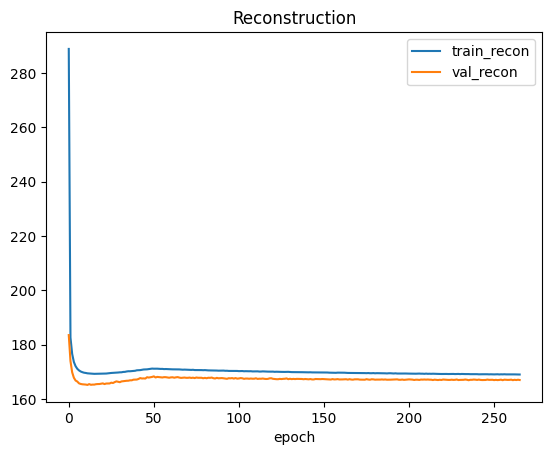

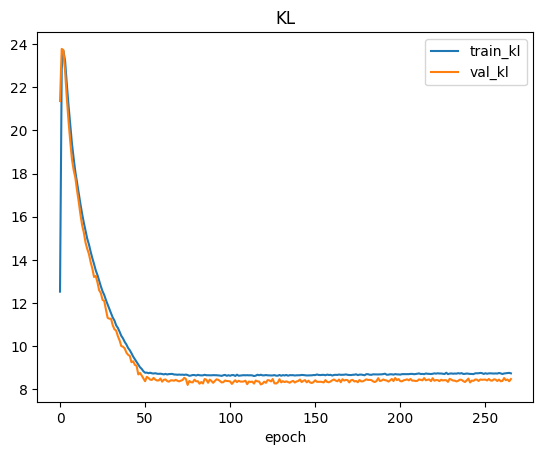

In [18]:
# --- gene selection: HVGs + exhaustion/stemness markers, minus TCR V/J genes ---
# TCR V/J genes are clone-specific -> patient-specific. In the first model they produced patient-only
# clusters that conditioning on patient could not remove (105 of them were in the HVG set)
markers = ["TCF7","SELL","IL7R","CCR7","LEF1","PDCD1","HAVCR2","LAG3","TOX","TIGIT","CTLA4","ENTPD1"]
is_tcr = adata.var_names.str.match(r"^TR[ABGD][VJ]")
adata.var["use_for_model"] = (adata.var["highly_variable"] | adata.var_names.isin(markers)) & ~is_tcr

adata_hvg = adata[:, adata.var["use_for_model"]].copy()
print(adata_hvg.n_vars, "genes for the model")
print("markers missing:", [g for g in markers if g not in adata_hvg.var_names])   # should be []
print("TCR genes left:", int(adata_hvg.var_names.str.match(r"^TR[ABGD][VJ]").sum()))  # should be 0

# --- train ---
# Condition on patient (nuisance variable). Day is deliberately NOT given to the model,
# so we can check afterwards whether the latent space tracks real time on its own
CONFIG.update(condition_key="patient", latent_dim=10, hidden_dims=[256, 128], batch_size=512)

# already normalized on all genes in the QC cell -> don't renormalize on the 2,000-gene subset
adata_hvg, X, C, cond_cats = prepare_data(adata_hvg, "patient", already_log_normalized=True)
print(X.shape, cond_cats, "device:", DEVICE)

train_loader, val_loader = make_loaders(X, C, CONFIG["val_fraction"], CONFIG["batch_size"])
model = CVAE(n_genes=X.shape[1], n_cond=C.shape[1],
             hidden_dims=CONFIG["hidden_dims"], latent_dim=CONFIG["latent_dim"],
             dropout=CONFIG["dropout"])

model, history = train_cvae(model, train_loader, val_loader, CONFIG)
history.plot(x="epoch", y=["train_recon", "val_recon"], title="Reconstruction")
# KL climbs while beta ~ 0 (warm-up), then is pulled down to ~1 per latent dim once beta = 1:
# the latent space is used (no posterior collapse)
history.plot(x="epoch", y=["train_kl", "val_kl"], title="KL")

torch.save(model.state_dict(), "/content/drive/MyDrive/cvae_cart_v2.pt")

## 6. The latent space
Patient should look mixed (conditioning worked). Timepoint should show structure, which the model learned without labels.

In [19]:
# 5. Embed + pseudotime
@torch.no_grad()
def get_latent(model, X, C, batch_size=1024):
    """Use the latent MEANS (not samples) as each cell's coordinates."""
    model.eval()
    mus = []
    for i in range(0, X.shape[0], batch_size):
        x = torch.from_numpy(X[i:i + batch_size]).to(DEVICE)
        c = torch.from_numpy(C[i:i + batch_size]).to(DEVICE)
        mu, _ = model.encoder(x, c)
        mus.append(mu.cpu().numpy())
    return np.vstack(mus)


def marker_score(adata, genes):
    """Mean z-scored expression of the markers present in the panel."""
    present = [g for g in genes if g in adata.var_names]
    if not present:
        raise ValueError(f"None of {genes} found in adata.var_names")
    sub = adata[:, present].X
    sub = sub.toarray() if sp.issparse(sub) else np.asarray(sub)
    z = (sub - sub.mean(0)) / (sub.std(0) + 1e-8)
    return z.mean(1), present


def embed_and_pseudotime(adata, Z):
    adata.obsm["X_cvae"] = Z
    sc.pp.neighbors(adata, use_rep="X_cvae")
    sc.tl.umap(adata)

    func, _ = marker_score(adata, FUNCTIONAL_MARKERS)
    exh, _ = marker_score(adata, EXHAUSTED_MARKERS)
    adata.obs["functional_score"] = func
    adata.obs["exhaustion_score"] = exh
    adata.obs["exh_minus_func"] = exh - func

    # Root diffusion pseudotime at the most functional / least exhausted cell
    sc.tl.diffmap(adata)
    adata.uns["iroot"] = int(np.argmin(adata.obs["exh_minus_func"].to_numpy()))
    sc.tl.dpt(adata)
    return adata

latent variance per dim: [0.9  0.63 0.63 0.77 0.81 0.82 0.89 0.55 0.5  0.83]


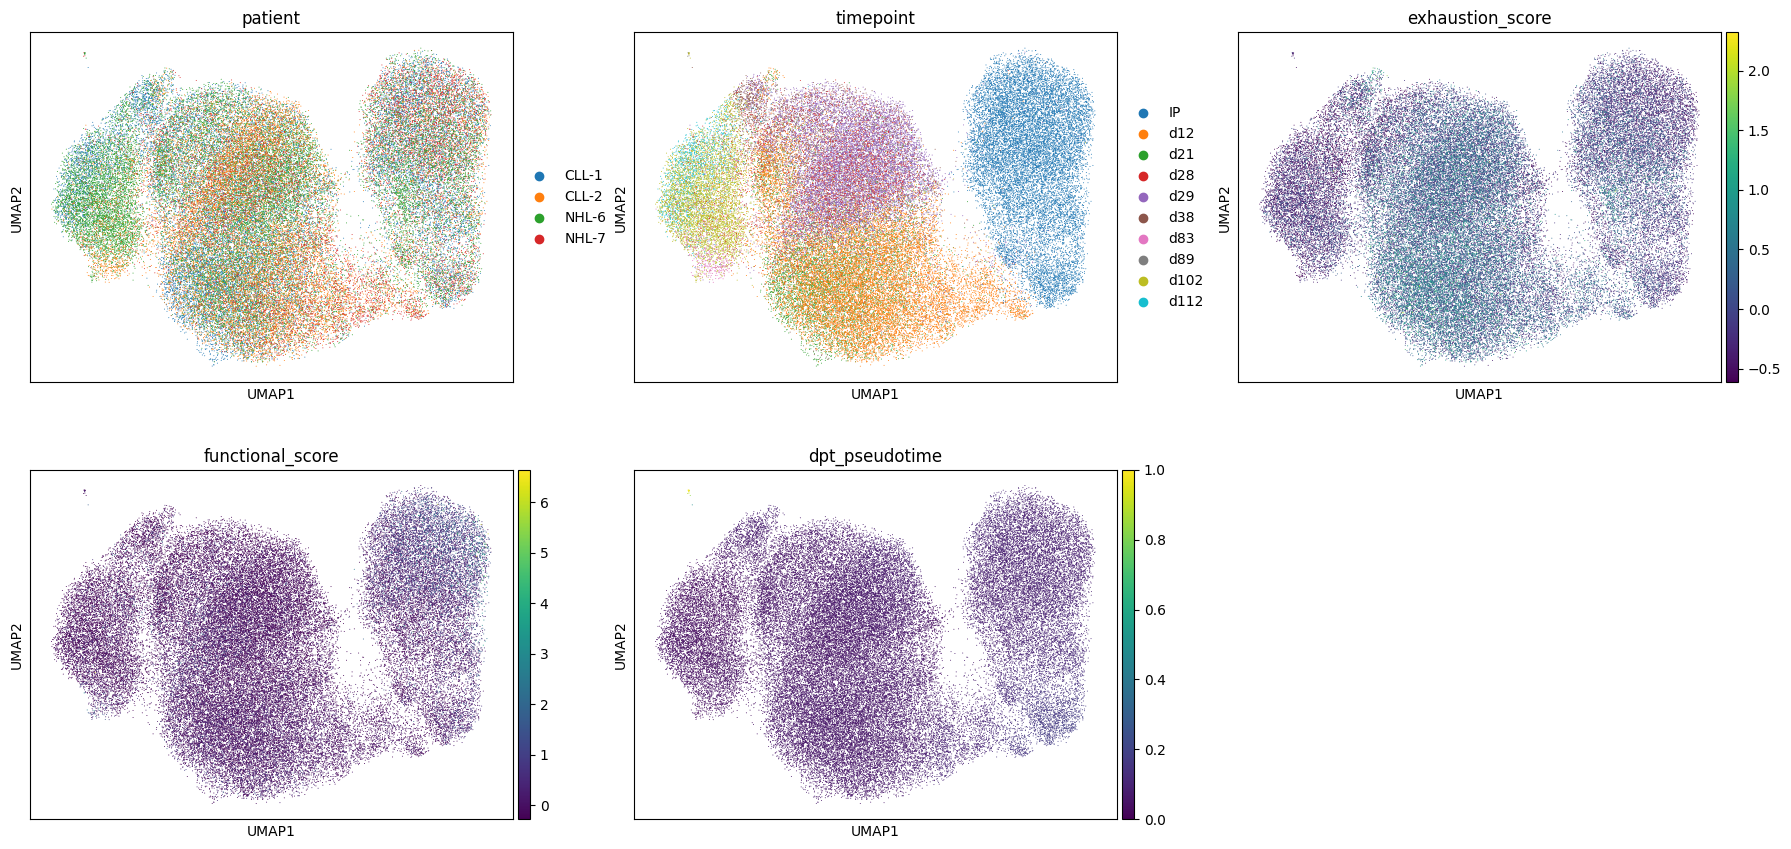

SignificanceResult(statistic=np.float64(-0.7406655417840763), pvalue=np.float64(0.0))


In [20]:
# Embed every cell by its latent mean, build UMAP + pseudotime on the latent space.
# NOTE: pseudotime here uses the default root (most 'functional' single cell), which landed on an outlier
# (rho = 0.21). The next cell re-roots it at the infusion product.
from scipy.stats import spearmanr

Z = get_latent(model, X, C)
print("latent variance per dim:", np.round(Z.var(0), 2))   # near 0 = unused dimension

adata_hvg.obs["day"] = adata.obs.loc[adata_hvg.obs_names, "day"].values   # make sure labels carried over
adata_hvg = embed_and_pseudotime(adata_hvg, Z)

sc.pl.umap(adata_hvg, color=["patient", "timepoint", "exhaustion_score",
                             "functional_score", "dpt_pseudotime"], ncols=3)

print(spearmanr(adata_hvg.obs["dpt_pseudotime"], adata_hvg.obs["day"]))
adata_hvg.write_h5ad("/content/drive/MyDrive/GSE125881_cvae_embedded.h5ad")

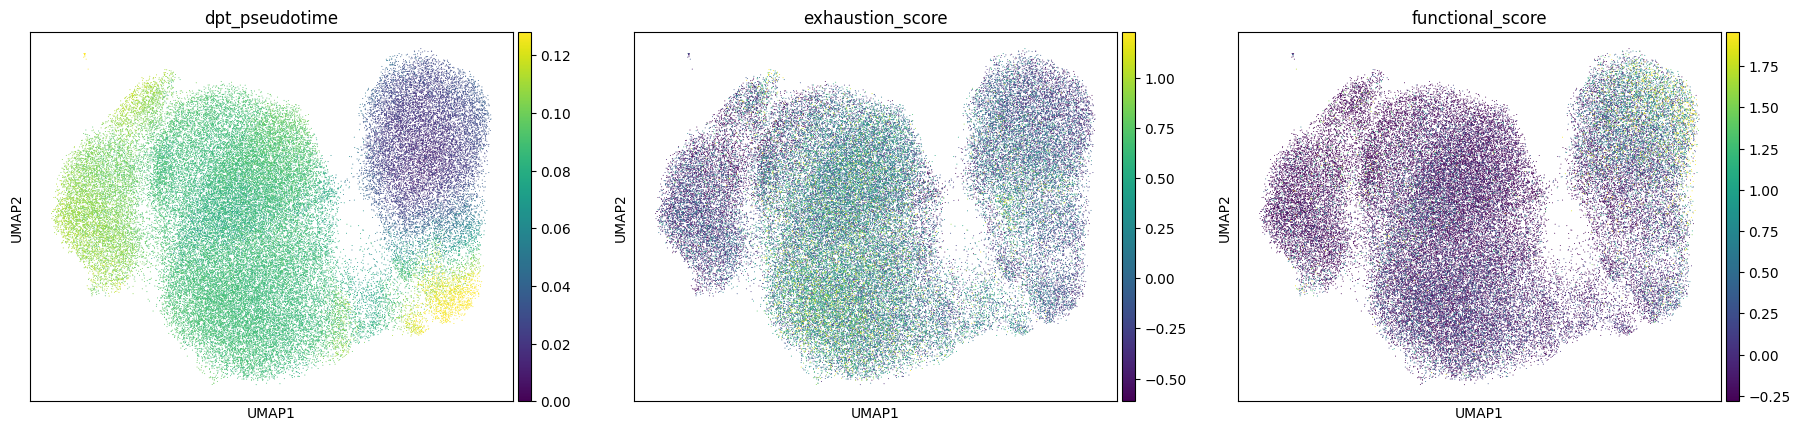

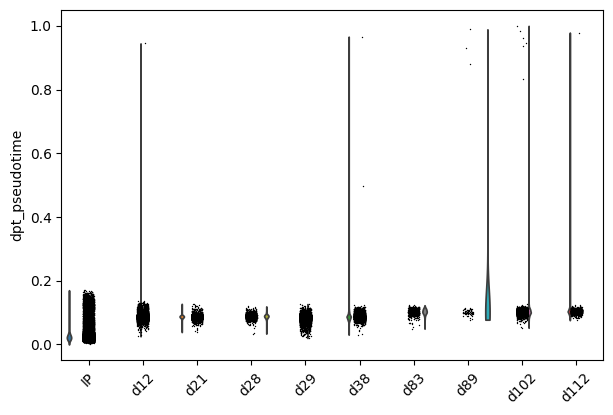

all cells: SignificanceResult(statistic=np.float64(0.5845202065406075), pvalue=np.float64(0.0))
CLL-1 0.63
CLL-2 0.32
NHL-6 0.66
NHL-7 0.61


In [21]:
# Root at the most typical infusion-product cell (closest to the IP centroid in diffusion space).
# Caveat: choosing the root uses the IP label, so the IP-vs-rest split is partly built in;
# the fair test is the post-infusion-only correlation in the next cell
dm = adata_hvg.obsm["X_diffmap"][:, 1:]                    # component 0 is trivial, skip it
ip = np.where(adata_hvg.obs["timepoint"] == "IP")[0]
centroid = dm[ip].mean(0)
adata_hvg.uns["iroot"] = int(ip[np.argmin(((dm[ip] - centroid) ** 2).sum(1))])
sc.tl.dpt(adata_hvg)

sc.pl.umap(adata_hvg, color=["dpt_pseudotime", "exhaustion_score", "functional_score"],
           vmax="p99", ncols=3)
sc.pl.violin(adata_hvg, "dpt_pseudotime", groupby="timepoint", rotation=45)

print("all cells:", spearmanr(adata_hvg.obs["dpt_pseudotime"], adata_hvg.obs["day"]))
# Does the trend hold inside each patient, not just across them?
for p in adata_hvg.obs["patient"].cat.categories:
    m = adata_hvg.obs["patient"] == p
    print(p, round(spearmanr(adata_hvg.obs.loc[m, "dpt_pseudotime"], adata_hvg.obs.loc[m, "day"])[0], 2))

post-infusion only: SignificanceResult(statistic=np.float64(0.34016878344071005), pvalue=np.float64(0.0))


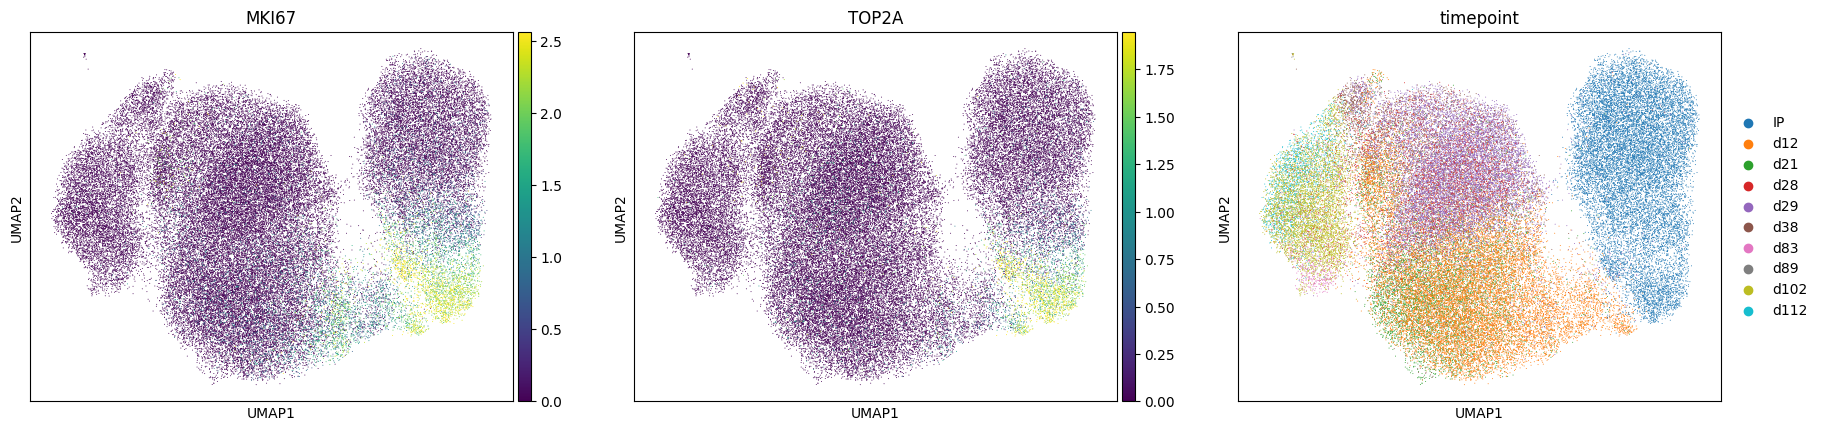

In [22]:
# Fair test: order of post-infusion timepoints only (nothing about these was given to model or root)
post = adata_hvg.obs["day"] > 0
print("post-infusion only:", spearmanr(adata_hvg.obs.loc[post, "dpt_pseudotime"],
                                       adata_hvg.obs.loc[post, "day"]))

# The high-pseudotime patch next to IP is proliferating cells (cell division forms its own branch)
sc.pl.umap(adata_hvg, color=["MKI67", "TOP2A", "timepoint"], vmax="p99", ncols=3)

0 TCR V/J genes in the model's gene set: []


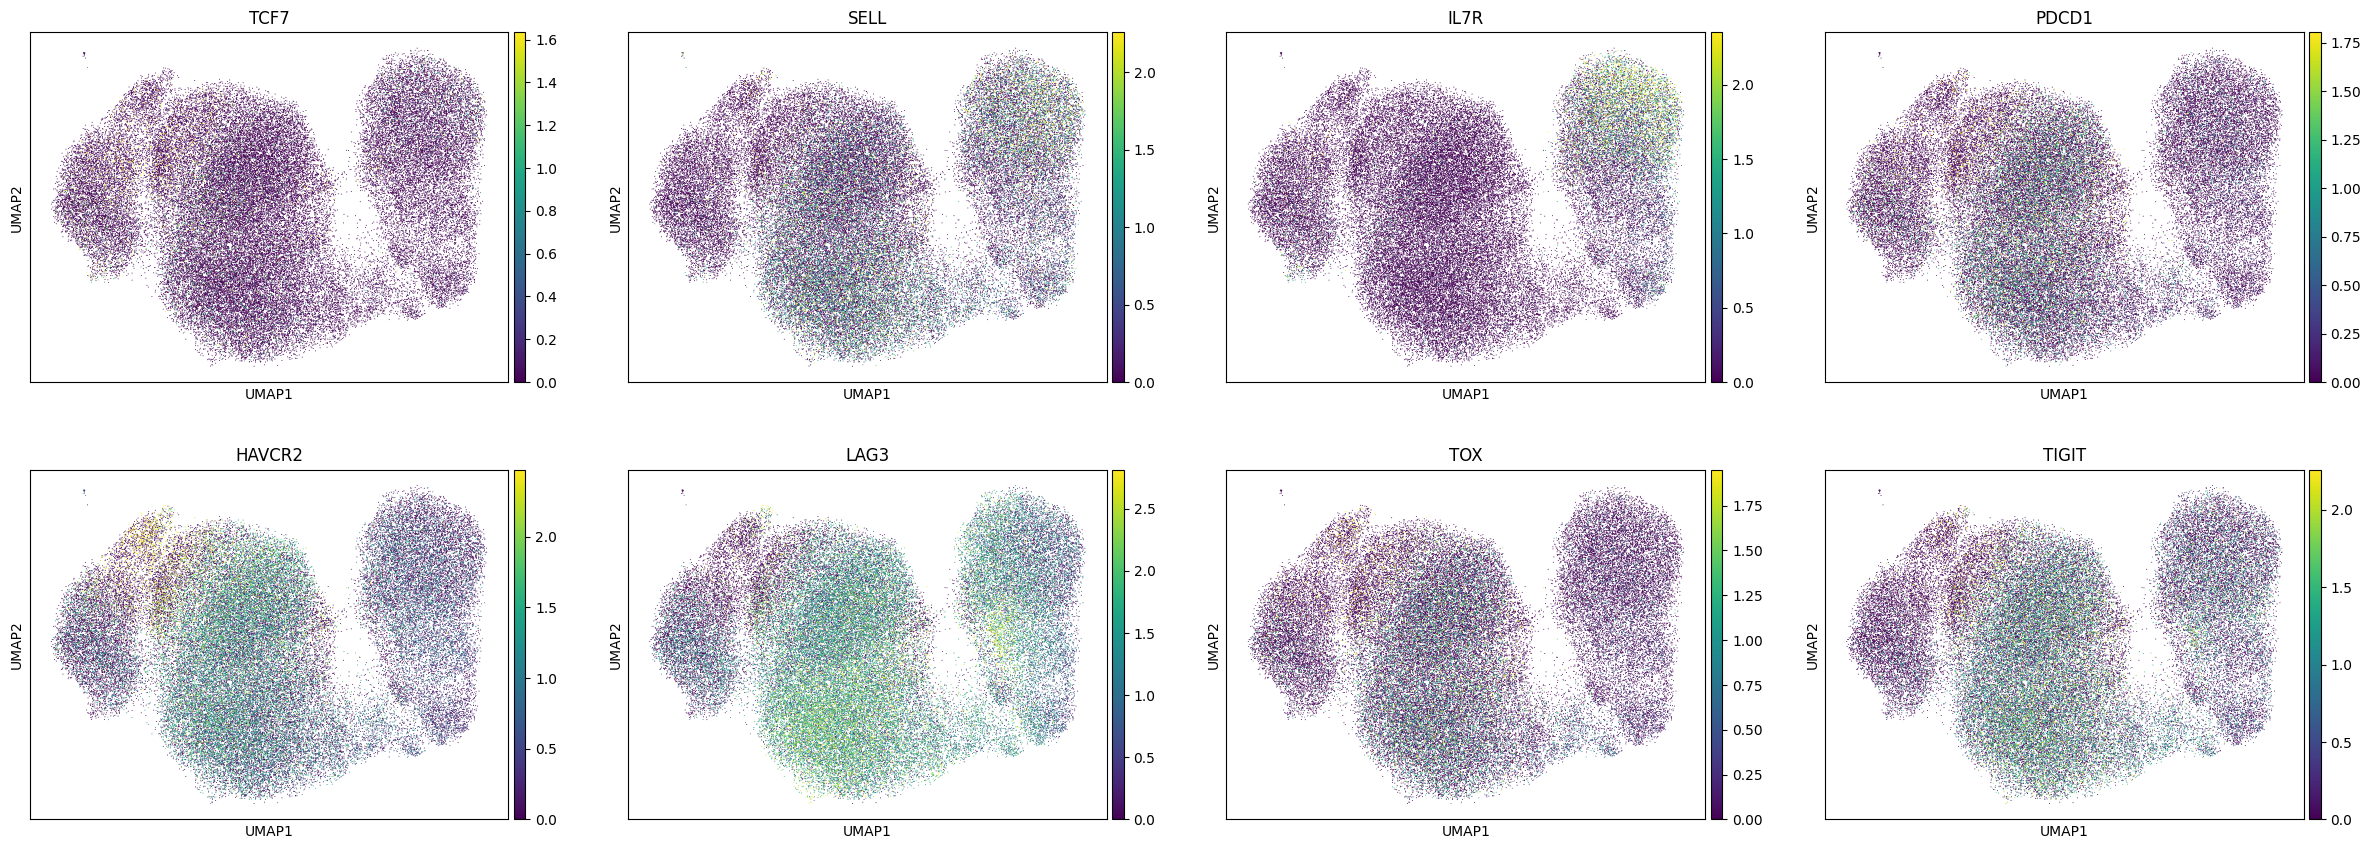

In [23]:
# Diagnostic: on the first model this printed 105 TCR V/J genes (-> removed for the final model)
# and errored because PDCD1 etc. weren't in the gene set. RERUN: should now print 0 and plot all 8 markers.
hv = adata_hvg.var_names
tcr = hv[hv.str.match(r"^TR[ABGD][VJ]")]
print(len(tcr), "TCR V/J genes in the model's gene set:", list(tcr[:15]))

# individual markers, with color scale clipped at the 99th percentile
sc.pl.umap(adata_hvg, color=["TCF7", "SELL", "IL7R", "PDCD1", "HAVCR2", "LAG3", "TOX", "TIGIT"],
           vmax="p99", ncols=4)

## 7. Decoding paths through latent space

In [24]:
# 6. Latent trajectory: functional -> exhausted
@torch.no_grad()
def latent_trajectory(model, adata, Z, cond_cats, condition, n_steps=20, quantile=0.1):
    """
    Start = centroid of the top `quantile` most functional cells,
    End   = centroid of the top `quantile` most exhausted cells.
    Linearly interpolate between them in latent space and decode every step
    under a single fixed condition, so only cell state changes along the path.
    """
    s = adata.obs["exh_minus_func"].to_numpy()
    lo, hi = np.quantile(s, [quantile, 1 - quantile])
    z_start = Z[s <= lo].mean(0)
    z_end = Z[s >= hi].mean(0)

    alphas = np.linspace(0, 1, n_steps, dtype=np.float32)
    z_path = np.stack([(1 - a) * z_start + a * z_end for a in alphas]).astype(np.float32)

    c_vec = np.zeros((n_steps, len(cond_cats)), dtype=np.float32)
    c_vec[:, cond_cats.index(condition)] = 1.0

    model.eval()
    x_path = model.decoder(torch.from_numpy(z_path).to(DEVICE),
                           torch.from_numpy(c_vec).to(DEVICE)).cpu().numpy()

    path_df = pd.DataFrame(x_path, columns=adata.var_names, index=np.round(alphas, 3))
    path_df.index.name = "alpha"

    change = path_df.iloc[-1] - path_df.iloc[0]
    ranking = pd.DataFrame({
        "start_expr": path_df.iloc[0],
        "end_expr": path_df.iloc[-1],
        "delta": change,
    }).sort_values("delta", ascending=False)
    return path_df, ranking

In [25]:
# Decode straight lines through latent space under a FIXED patient (CLL-1), so only cell state changes.
# Path A (as designed): most functional cells -> most exhausted cells.
#   Result: really memory -> cytotoxic/NK-like effector; PDCD1/HAVCR2/TOX don't top the list
path_a, rank_a = latent_trajectory(model, adata_hvg, Z, cond_cats, condition="CLL-1")
print("UP along functional -> exhausted:\n", rank_a.head(15)[["delta"]])
print("DOWN:\n", rank_a.tail(10)[["delta"]])

# Path B (time-based): infusion product -> very late timepoints (day >= 83), cycling cells excluded
@torch.no_grad()
def decode_path(z_start, z_end, condition, n_steps=20):
    alphas = np.linspace(0, 1, n_steps, dtype=np.float32)
    z = np.stack([(1 - a) * z_start + a * z_end for a in alphas]).astype(np.float32)
    c = np.zeros((n_steps, len(cond_cats)), dtype=np.float32)
    c[:, cond_cats.index(condition)] = 1.0
    model.eval()
    x = model.decoder(torch.from_numpy(z).to(DEVICE), torch.from_numpy(c).to(DEVICE)).cpu().numpy()
    df = pd.DataFrame(x, columns=adata_hvg.var_names, index=np.round(alphas, 2))
    return df, (df.iloc[-1] - df.iloc[0]).sort_values(ascending=False)

day = adata_hvg.obs["day"].to_numpy()
cycling = adata_hvg[:, "MKI67"].X.toarray().ravel() > 0 if hasattr(adata_hvg.X, "toarray") \
          else np.asarray(adata_hvg[:, "MKI67"].X).ravel() > 0
path_b, delta_b = decode_path(Z[(day == 0) & ~cycling].mean(0),
                              Z[(day >= 83) & ~cycling].mean(0), condition="CLL-1")
print("UP from IP -> late:\n", delta_b.head(15).round(2))
print("DOWN:\n", delta_b.tail(10).round(2))

UP along functional -> exhausted:
            delta
NKG7    2.057117
CMC1    1.909983
GZMB    1.838093
GZMH    1.835375
CST7    1.723776
CCL4    1.615816
GZMK    1.383934
GNLY    1.311416
CD74    1.241412
PRF1    1.221764
KLRC1   1.196423
DUSP2   1.089880
PLEK    1.042227
MT2A    0.926841
S100A4  0.900541
DOWN:
           delta
HOPX  -1.133085
MIF   -1.154900
EGLN3 -1.190306
GAPDH -1.210386
JUN   -1.222862
GPI   -1.230788
ENO1  -1.391946
TPI1  -1.489444
LDHA  -1.533062
LTB   -2.019347
UP from IP -> late:
 CMC1         2.14
GNLY         2.05
CXCR4        1.58
MTRNR2L12    1.54
RPL41        1.47
NKG7         1.26
MT-ND3       1.25
RPS27        1.24
GZMH         1.08
MT-ATP6      0.91
PIK3R1       0.89
FTH1         0.88
NFKBIA       0.84
ZFP36L2      0.82
MT-ND2       0.82
dtype: float32
DOWN:
 LDHA    -2.15
GPI     -2.16
PKM     -2.23
ACTB    -2.23
ACTG1   -2.38
TPI1    -2.55
LTB     -2.73
GZMA    -2.79
ENO1    -2.87
IL32    -3.47
dtype: float32


## 8. Do the decoded genes match real expression?

In [26]:
# Mito/ribosomal genes track cell quality and depth, not biology: drop from rankings
noise = adata.var_names.str.match(r"^(MT-|RPL|RPS|MTRNR)")
delta_b_clean = delta_b[~delta_b.index.str.match(r"^(MT-|RPL|RPS|MTRNR)")]

# Check the decoder against real data: Wilcoxon DE late vs IP on the full log-normalized data, non-cycling cells.
# (p-values are inflated: cells from the same patient aren't independent; see the per-patient check below)
cyc_all = np.asarray(adata[:, "MKI67"].X.todense()).ravel() > 0
sub = adata[((adata.obs["day"] == 0) | (adata.obs["day"] >= 83)) & ~cyc_all, ~noise].copy()
sub.obs["group"] = np.where(sub.obs["day"] == 0, "IP", "late")
sc.tl.rank_genes_groups(sub, "group", reference="IP", method="wilcoxon")
de = sc.get.rank_genes_groups_df(sub, group="late").set_index("names")

top_model = list(delta_b_clean.head(20).index) + list(delta_b_clean.tail(20).index)
check = pd.DataFrame({"model_delta": delta_b_clean[top_model].round(2),
                      "real_logFC": de.loc[top_model, "logfoldchanges"].round(2),
                      "padj": de.loc[top_model, "pvals_adj"]})
check["agrees"] = np.sign(check["model_delta"]) == np.sign(check["real_logFC"])
print(check.to_string())
print("direction agreement:", check["agrees"].mean().round(2))

         model_delta  real_logFC           padj  agrees
CMC1            2.14        2.48   0.000000e+00    True
GNLY            2.05        2.86   0.000000e+00    True
CXCR4           1.58        2.68   0.000000e+00    True
NKG7            1.26        1.65   0.000000e+00    True
GZMH            1.08        5.27   0.000000e+00    True
PIK3R1          0.89        2.50   0.000000e+00    True
FTH1            0.88        0.24  7.534199e-277    True
NFKBIA          0.84        2.32   0.000000e+00    True
ZFP36L2         0.82        0.91   0.000000e+00    True
TNFAIP3         0.81        1.98   0.000000e+00    True
TXNIP           0.78        0.56  1.705918e-235    True
DDX6            0.75        2.14   0.000000e+00    True
GZMK            0.73        0.34   3.940547e-08    True
SPOCK2          0.67        0.71   9.031644e-52    True
DUSP2           0.64        2.24   0.000000e+00    True
CBLB            0.60        1.80   0.000000e+00    True
GCC2            0.58        0.63   2.870743e-36 

In [27]:
# Statistically honest check: n = 4 patients, not 20k cells. A gene counts as a finding only if it moves
# the same direction in every patient. Result: 36/40 (all 20 'down' genes, 16/20 'up')
genes = check.index.tolist()
per_pt = {}
for p in sub.obs["patient"].cat.categories:
    s = sub[sub.obs["patient"] == p]
    late = np.asarray(s[s.obs["group"] == "late", genes].X.mean(0)).ravel()
    ip   = np.asarray(s[s.obs["group"] == "IP",   genes].X.mean(0)).ravel()
    per_pt[p] = late - ip
per_pt = pd.DataFrame(per_pt, index=genes).round(2)
per_pt["consistent"] = (np.sign(per_pt).nunique(axis=1) == 1)
print(per_pt.to_string())
print(per_pt["consistent"].sum(), "/", len(genes), "genes same direction in all 4 patients")

         CLL-1  CLL-2  NHL-6  NHL-7  consistent
CMC1      1.49   0.50   0.49   0.09        True
GNLY      1.04   2.35   1.91   1.39        True
CXCR4     1.08   1.29   0.97   1.03        True
NKG7      0.54   1.31   1.15   0.70        True
GZMH      0.94   1.53   1.49   1.16        True
PIK3R1    0.64   1.29   1.03   0.77        True
FTH1      0.25   0.62   0.14   0.24        True
NFKBIA    0.67   1.70   1.11   1.39        True
ZFP36L2   0.42   0.45   0.65   0.20        True
TNFAIP3   0.67   1.27   1.05   1.38        True
TXNIP     0.66  -0.11   0.32  -0.00       False
DDX6      0.68   0.62   0.79   0.24        True
GZMK     -0.11   0.67  -0.11   0.16       False
SPOCK2    0.45   0.37   0.12  -0.20       False
DUSP2     0.23   1.20   1.40   0.70        True
CBLB      0.56   0.49   0.62   0.54        True
GCC2      0.63  -0.09   0.02  -0.23       False
CCL4      0.26   1.46   0.49   0.54        True
AAK1      0.53   0.36   0.35   0.13        True
RNF19A    0.48   0.48   0.25   0.55     

In [28]:
# 7. Counterfactual: swap condition (defined for future use; not run yet)
@torch.no_grad()
def counterfactual(model, X, C, cond_cats, from_cond, to_cond, var_names):
    """Encode cells from `from_cond`, decode them as if they were `to_cond`."""
    model.eval()
    mask = C[:, cond_cats.index(from_cond)] == 1
    x = torch.from_numpy(X[mask]).to(DEVICE)
    c_from = torch.from_numpy(C[mask]).to(DEVICE)
    mu, _ = model.encoder(x, c_from)

    c_to = torch.zeros_like(c_from)
    c_to[:, cond_cats.index(to_cond)] = 1.0

    x_orig = model.decoder(mu, c_from).cpu().numpy()
    x_cf = model.decoder(mu, c_to).cpu().numpy()
    return pd.DataFrame({
        "decoded_as_" + str(from_cond): x_orig.mean(0),
        "decoded_as_" + str(to_cond): x_cf.mean(0),
        "delta": (x_cf - x_orig).mean(0),
    }, index=var_names).sort_values("delta", ascending=False)

## Summary
- Pseudotime on the latent space vs. actual day: Spearman ρ = 0.54 overall (0.58–0.61 in 3 of 4 patients); 0.26 within post-infusion timepoints, so mostly an infusion-product vs. post-infusion split.
- Decoded IP → late trajectory matched real differential expression for 40/40 top genes; 36/40 changed the same direction in all 4 patients.
- Biology: hypoxia/glycolysis genes (EGLN3, PGK1, LDHA, ENO1…) and activation genes (FOS, CD69) fall; quiescence (CXCR4, CBLB, TNFAIP3) and NK-like cytotoxic genes (GNLY, NKG7, GZMH) rise. No progressive rise in classic exhaustion markers, consistent with the original study.
- Caveat: infusion-product cells come from culture, later cells from blood, so time is confounded with environment; the hypoxia signature points to culture.